Retail Dataset:

   Branch       City  Gender            Product line      Payment PurchaseType
0       A     Yangon  Female       Health and beauty      Ewallet          Yes
1       C  Naypyitaw  Female  Electronic accessories         Cash           No
2       A     Yangon    Male      Home and lifestyle  Credit card           No
3       A     Yangon    Male       Health and beauty      Ewallet          Yes
4       A     Yangon    Male       Sports and travel      Ewallet           No
5       C  Naypyitaw    Male  Electronic accessories      Ewallet           No
6       A     Yangon  Female  Electronic accessories      Ewallet          Yes
7       C  Naypyitaw  Female      Home and lifestyle      Ewallet           No
8       A     Yangon  Female       Health and beauty  Credit card          Yes
9       B   Mandalay  Female      Food and beverages  Credit card          Yes
10      B   Mandalay  Female     Fashion accessories      Ewallet          Yes
11      B   Mandalay    Male  Elect

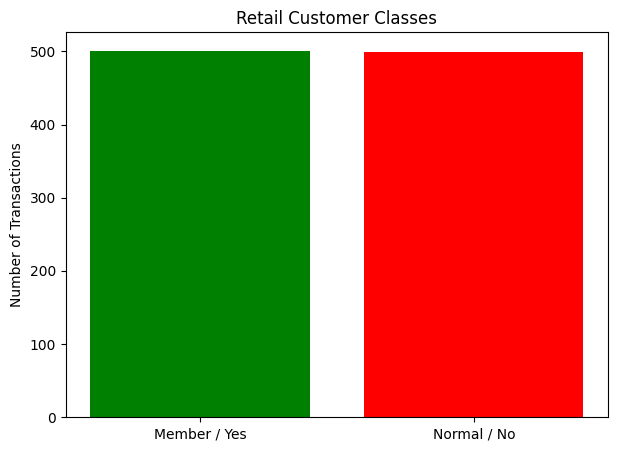

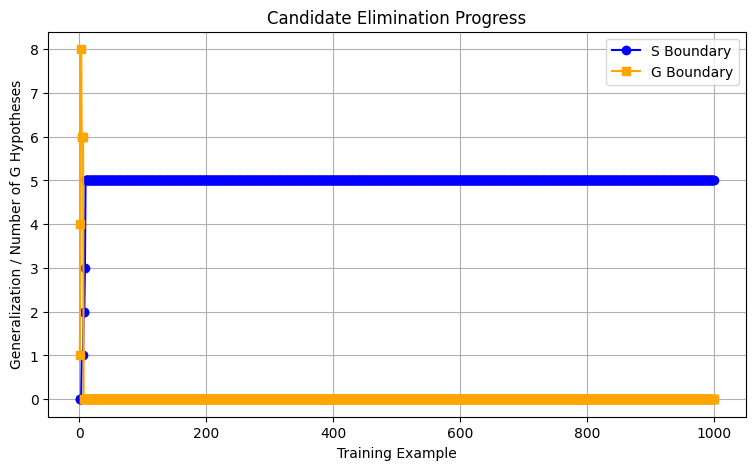

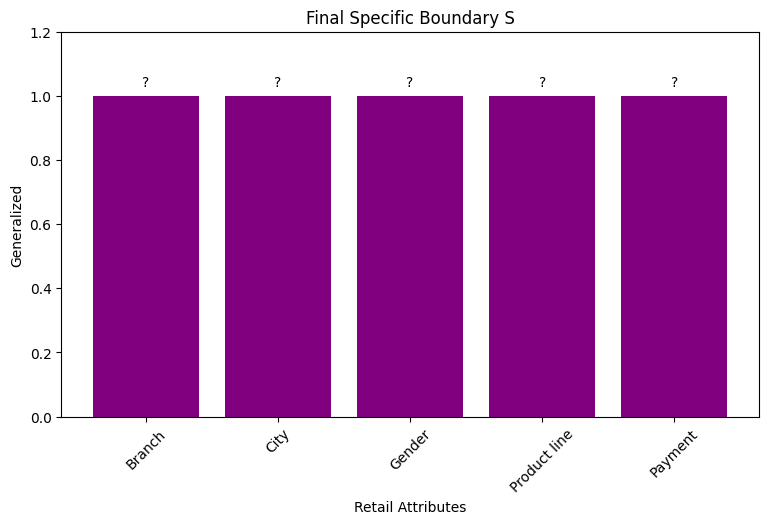

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/selva86/datasets/master/supermarket_sales.csv"

data = pd.read_csv(DATA_URL)

data.columns = data.columns.str.strip()

data = data[
    [
        "Branch",
        "City",
        "Customer type",
        "Gender",
        "Product line",
        "Payment"
    ]
].copy()

data["PurchaseType"] = data["Customer type"].map({
    "Member": "Yes",
    "Normal": "No"
})

data = data.drop(columns=["Customer type"])

print("Retail Dataset:\n")
print(data.head(20))

attributes = list(data.columns[:-1])
target = data.columns[-1]

S = ['0'] * len(attributes)
G = [['?'] * len(attributes)]

S_history = []
G_history = []


def covers(hypothesis, example):

    for h, e in zip(hypothesis, example):

        if h != '?' and h != '0' and h != e:
            return False

    return True


def more_general_or_equal(h1, h2):

    for a, b in zip(h1, h2):

        if a != '?' and a != b:
            return False

    return True


for index, row in data.iterrows():

    example = list(row[attributes])
    label = str(row[target]).strip()

    if label == "Yes":

        for i in range(len(attributes)):

            if S[i] == '0':
                S[i] = example[i]

            elif S[i] != example[i]:
                S[i] = '?'

        G = [
            g for g in G
            if covers(g, example)
        ]

    elif label == "No":

        new_G = []

        for g in G:

            if covers(g, example):

                for i in range(len(attributes)):

                    if g[i] == '?':

                        values = data[attributes[i]].unique()

                        for value in values:

                            if value != example[i]:

                                new_hypothesis = g.copy()

                                new_hypothesis[i] = value

                                if more_general_or_equal(
                                    new_hypothesis,
                                    S
                                ):
                                    new_G.append(
                                        new_hypothesis
                                    )

            else:
                new_G.append(g)

        G = new_G

    S_history.append(S.copy())
    G_history.append(len(G))

    if index < 20:

        print("\nExample", index + 1)

        if label == "Yes":
            print("Class: Positive")
        else:
            print("Class: Negative")

        print("S:", S)
        print("G:", G)


print("\n" + "=" * 60)
print("FINAL CANDIDATE ELIMINATION RESULT")
print("=" * 60)

print("\nSpecific Boundary S:")

for attribute, value in zip(attributes, S):
    print(attribute, ":", value)

print("\nGeneral Boundary G:")

for g in G:
    print(g)


positive_count = (
    data[target] == "Yes"
).sum()

negative_count = (
    data[target] == "No"
).sum()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Member / Yes", "Normal / No"],
    [positive_count, negative_count],
    color=["green", "red"]
)

plt.title("Retail Customer Classes")
plt.ylabel("Number of Transactions")

plt.show()


plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(S_history) + 1),
    [h.count('?') for h in S_history],
    color="blue",
    marker="o",
    label="S Boundary"
)

plt.plot(
    range(1, len(G_history) + 1),
    G_history,
    color="orange",
    marker="s",
    label="G Boundary"
)

plt.title("Candidate Elimination Progress")
plt.xlabel("Training Example")
plt.ylabel("Generalization / Number of G Hypotheses")

plt.legend()
plt.grid(True)

plt.show()


final_generalization = [
    1 if value == '?' else 0
    for value in S
]

plt.figure(figsize=(9, 5))

plt.bar(
    attributes,
    final_generalization,
    color="purple"
)

plt.title("Final Specific Boundary S")
plt.xlabel("Retail Attributes")
plt.ylabel("Generalized")

plt.ylim(0, 1.2)

for i, value in enumerate(final_generalization):

    label = "?" if value == 1 else S[i]

    plt.text(
        i,
        value + 0.03,
        label,
        ha="center"
    )

plt.xticks(rotation=45)

plt.show()
